# Fine-tuning BERT for text classification quest

**Увага**: Тренування моделі буде значно швидшим на GPU. Активуйте його в Colab (Runtime -> Change runtime type -> A100 або L4 GPU)

In [18]:
import lpnlp

lab = lpnlp.start(
    email="sviatoslav.humeniuk.shi.2023@lpnu.ua",
    lab="quest_text_classification",
    size=500
)

Удачі!


In [19]:
sorted(lab.files.keys())

['metadata.json',
 'test.txt',
 'train.labels',
 'train.txt',
 'valid.labels',
 'valid.txt']

In [20]:
import json
from sklearn.utils import shuffle

train_X = lab.files["train.txt"].splitlines()
train_y = lab.files["train.labels"].splitlines()
train_X, train_y = shuffle(train_X, train_y, random_state=42)
valid_X = lab.files["valid.txt"].splitlines()
valid_y = lab.files["valid.labels"].splitlines()
test_X = lab.files["test.txt"].splitlines()
meta = json.loads(lab.files["metadata.json"])

In [21]:
train_X[:3]

['Maybe this is one of the most famous books in classical econometrics now at graduate level. Different from other overwhelming econometrics text books (e.g., Greene), this textbook is very readable and still practical. I liked it.',
 'I have tried on more than one occasion to like this movie. It is beautiful to look at of course and worth seeing it just for the scenery. But, Redford just missed the boat on directing it. It just doesn\'t hold the interest. The pace is so slow most of the time that you could doze off and there seem to be odd things thrown in for no particular reason. Brad Pitt was too young, with too little depth as an actor to put everything into the role that needed to be there. He just comes across as a rather delinquent personality with no real depth. Pretty much a tragedy looking for a place to happen from the time he was just a kid. I think the test of any movie is "does it grab you and hold you from the first scene?". This movie does not.',
 'my friend said to re

In [22]:
train_y[:3]

['1', '0', '0']

In [23]:
import datasets

dataset = datasets.DatasetDict({
    "train": datasets.Dataset.from_dict({
        "text": train_X,
        "label": [int(y) for y in train_y],
    }),
    "validation": datasets.Dataset.from_dict({
        "text": valid_X,
        "label": [int(y) for y in valid_y],
    }),
    "test": datasets.Dataset.from_dict({
        "text": test_X,
    }),
})

In [24]:
from PIL import Image
import math
import json

def predictions_to_image(predictions, meta):
    labels = sorted(set(predictions))
    image_size = int(math.sqrt(len(predictions)))
    image = Image.new("P", (image_size, image_size))
    image.putpalette(meta["palette"])
    image.putdata([labels.index(prediction) for prediction in predictions])

    image = image.convert("RGB")

    return image


# Тренування моделі

Ми вже бачили класифікатори на логістичній регресії, які використовували мішок слів та мішок ембедингів. Тепер дотренуємо BERT або його більш сучасну версію (ModernBERT, Etin) за допомогою бібліотеки HuggingFace transformers.

Корисні посилання:
- https://www.philschmid.de/fine-tune-modern-bert-in-2025
- https://huggingface.co/learn/llm-course/chapter3

Також розпитуйте свою LLM, щоб зрозуміти, що відбувається.

In [25]:
import numpy as np
import transformers
from sklearn.metrics import accuracy_score, f1_score

MODEL_NAME = "answerdotai/ModernBERT-base"
MAX_LENGTH = 256

In [26]:
tokenizer = transformers.AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

tokenized_dataset = dataset.map(tokenize, batched=True, remove_columns=["text"])

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/9216 [00:00<?, ? examples/s]

In [27]:
model = transformers.AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(set(dataset["train"]["label"])),
)

Loading weights:   0%|          | 0/136 [00:00<?, ?it/s]

[transformers] ModernBertForSequenceClassification LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     | 
------------------+------------+-
decoder.bias      | UNEXPECTED | 
classifier.bias   | MISSING    | 
classifier.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [28]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1": f1_score(labels, predictions, average="macro"),
    }

In [29]:
training_args = transformers.TrainingArguments(
    output_dir="bert-classifier",
    num_train_epochs=3,
    learning_rate=5e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    eval_strategy="epoch",
    save_strategy="no",
    report_to="none",
)

trainer = transformers.Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)

In [30]:
train_result = trainer.train()

d:\study\nlp\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,No log,0.428613,0.850000,0.847173
2,No log,0.548226,0.916000,0.915879
3,No log,0.544078,0.918000,0.917894


d:\study\nlp\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\study\nlp\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


In [31]:
bert_metrics = trainer.evaluate()
bert_metrics

d:\study\nlp\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,F1
No log,0.544078,3,0.918000,0.917894


{'eval_loss': 0.5440777540206909,
 'eval_accuracy': 0.918,
 'eval_f1': 0.9178935900927603}

In [32]:
classifier = transformers.pipeline(
    "text-classification",
    model=trainer.model,
    tokenizer=tokenizer,
    device=trainer.model.device,
)

## Тест

В тестових даних закодовано малюнок. Кожен позитивний відгук стає білим пікселем, а негативний - чорним.

Якщо ваша модель натренована достатньо якісно, то малюнок можна розгледіти.

Відповідь на це завдання - що зображено на малюнку? (одним словом, українською або англійською)

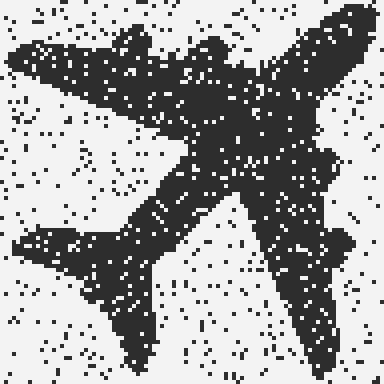

In [33]:
predictions = [
    y["label"]
    for y in classifier(test_X, batch_size=32, truncation=True, max_length=MAX_LENGTH)
]

image = predictions_to_image(predictions, meta)
display(image.resize((image.width * 4, image.height * 4), Image.NEAREST))

In [40]:
lab.answer("Airplane")

Відповідь правильна ✅
Вірно! 🚀 Лаба зараховується.


# Додаткове завдання

Натренуйте простий класифікатор на логістичній регресії. Наскільки відрізняється якість від BERT або ModernBERT? Швидкість тренування? Швидкість передбачення?

In [35]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

baseline = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2),
    LogisticRegression(max_iter=1000),
)

In [36]:
baseline.fit(train_X, train_y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidfvectorizer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[<U1](2,)","['0','1']"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'


In [37]:
baseline_predictions = baseline.predict(valid_X)

In [38]:
pd.DataFrame(
    {
        "Accuracy": [
            accuracy_score(valid_y, baseline_predictions),
            bert_metrics["eval_accuracy"],
        ],
        "F1": [
            f1_score(valid_y, baseline_predictions, average="macro"),
            bert_metrics["eval_f1"],
        ],
    },
    index=["Логістична регресія", "ModernBERT"],
).round(3)

,Accuracy,F1
Логістична регресія,0.782,0.782
ModernBERT,0.918,0.918


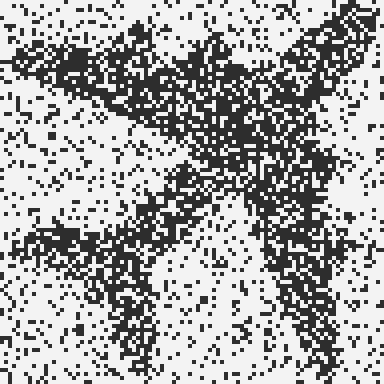

In [39]:
baseline_image = predictions_to_image(list(baseline.predict(test_X)), meta)
display(baseline_image.resize((baseline_image.width * 4, baseline_image.height * 4), Image.NEAREST))